# SHAP - top 10 features for M1, M2, M3, and the Final ensemble

Uses the **real, freshly-trained primary-analysis pipeline** (same training code as
`Train_3SubModels.ipynb`, run here again rather than loading the saved
`saved_models/primary/pipeline.joblib` - that file was pickled under a newer
scikit-learn and breaks on this environment's scikit-learn 1.7.2, so re-fitting here
guarantees the SHAP numbers below come from a model that actually runs) and the
**real test set** - nothing here is simulated or hand-picked.

* **M1 and M2** are XGBoost models (M1's stacker, M2's classifier), so their SHAP values are computed with **xgboost's own native
  `pred_contribs=True`** (exact TreeSHAP). This sidesteps a real, separately-confirmed
  bug in this environment: `shap.TreeExplainer` cannot parse xgboost 3.2.0's
  `base_score` string format and raises `ValueError`. Native xgboost contributions are
  mathematically identical to what `shap.TreeExplainer` would produce and do not
  depend on the `shap` package at all.
* **Final** is a 3-input logistic regression on logit(M1)/logit(M2)/logit(M3), so it
  has no direct notion of the 30 clinical features. To get a top-10 **feature** plot
  for Final (not just 3 bars for M1/M2/M3), this notebook explains the *whole pipeline*
  end-to-end with a model-agnostic permutation explainer (`shap.Explainer(...,
  algorithm="permutation")`), which only calls `predict_pipeline` as a black box and
  never touches the broken xgboost-loading code path.

**Runtime:** M1/M2/M3 sections take seconds. The Final section calls the full pipeline
many times per patient (permutation SHAP) - budget **~10-15 minutes** for all 181 test
patients on a normal laptop. `N_EXPLAIN`/`N_BACKGROUND` below can be lowered for a
quicker, slightly noisier look.

**Run `01_Data_Audit.ipynb` first** if you have not already (writes `config.json`).

In [ ]:
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import xgboost as xgb

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

BASE_DIR = os.getcwd()   # run from the repository root
OUT_DIR  = BASE_DIR
with open(os.path.join(OUT_DIR, "config.json")) as fh:
    CFG = json.load(fh)
FEATURES = CFG["features"]
COLS     = FEATURES + ["age", "sex"]

SHAP_DIR = os.path.join(OUT_DIR, "SHAP_Results")
os.makedirs(SHAP_DIR, exist_ok=True)

N_JOBS      = -1     # for run_oof/train_final
N_BACKGROUND = 40    # patients used as the permutation background for the Final explainer
N_EXPLAIN    = None  # None = explain all test patients; set e.g. 60 for a quicker run

import sys, importlib
sys.path.insert(0, OUT_DIR)
import min16_lib as lib
importlib.reload(lib)
print(f"CV {lib.N_SPLITS}x{lib.N_REPEATS}, seed {lib.RANDOM_STATE}")

CV 5x3, seed 42


## 1. Plot style (matches the earlier SHAP bar-chart figures)

In [ ]:
BAR_COLORS = ["#EE6C4D", "#36C3D1", "#E8C170", "#8FBC94", "#3D5A80",
              "#C9B8E8", "#A5668B", "#F4A261", "#D8A7B1", "#A8DADC"]

def plot_top10(mean_abs_shap, title, save_path):
    """mean_abs_shap: pandas Series indexed by feature name."""
    top = mean_abs_shap.sort_values(ascending=False).head(10)
    fig, ax = plt.subplots(figsize=(8.5, 5.2))
    ax.bar(range(len(top)), top.values, color=BAR_COLORS[:len(top)], edgecolor="black", linewidth=1.1)
    ax.set_xticks(range(len(top)))
    ax.set_xticklabels(top.index, rotation=90)
    ax.set_ylabel("Mean |SHAP value|")
    ax.set_title(title, fontweight="bold")
    ax.set_ylim(0, top.values.max() * 1.12)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    fig.patch.set_linewidth(3); fig.patch.set_edgecolor("black")
    plt.tight_layout()
    fig.savefig(save_path + ".png", dpi=150, bbox_inches="tight", edgecolor=fig.get_edgecolor())
    fig.savefig(save_path + ".svg", bbox_inches="tight")
    plt.show()
    return top

## 2. Fit the primary-analysis pipeline (same code/data as `Train_3SubModels.ipynb`)

In [ ]:
def load(path, max_patno=None):
    d = pd.read_csv(path)
    if max_patno is not None:
        d = d[d.PATNO < max_patno]
    d = d.reset_index(drop=True)
    X = pd.DataFrame({f: pd.to_numeric(d[f], errors="coerce") for f in FEATURES})
    X["age"] = d["Age"].astype(float)
    X["sex"] = d["Sex"].map({1: 0, 2: 1}).astype(float)      # 0 = male, 1 = female
    y = (d["APPRDX"] == 1).astype(int).values                 # 1 = PD, 0 = healthy
    return X[COLS], y, d["PATNO"].values, d["EVENT_ID"].values

X, y, g, _      = load(CFG["train_file"], CFG["new_cohort_min_patno"])
Xt, yt, gt, evt = load(CFG["test_file"], CFG["new_cohort_min_patno"])
print(f"train: {len(np.unique(g))} patients, {len(X)} visits")
print(f"test : {len(np.unique(gt))} patients, {len(Xt)} visits")

t0 = time.time()
feat_p, oof = lib.run_oof(X, y, g, FEATURES, N_JOBS)
print(f"OOF done ({time.time()-t0:.0f}s)")
B = lib.train_final(X, y, g, feat_p, oof, FEATURES, CFG, N_JOBS)
print(f"final models fitted ({time.time()-t0:.0f}s); threshold = {B['threshold']:.3f}")

prof_test = lib.unit_mean(gt, Xt[COLS])[COLS]     # one row per test patient, raw (un-imputed) values
print("test patient profiles:", prof_test.shape)

train: 501 patients, 3229 visits
test : 123 patients, 819 visits


OOF done (10s)


final models fitted (18s); threshold = 0.611
test patient profiles: (123, 32)


## 3. M1 - stacker SHAP (native xgboost TreeSHAP on the 30 per-feature probabilities)

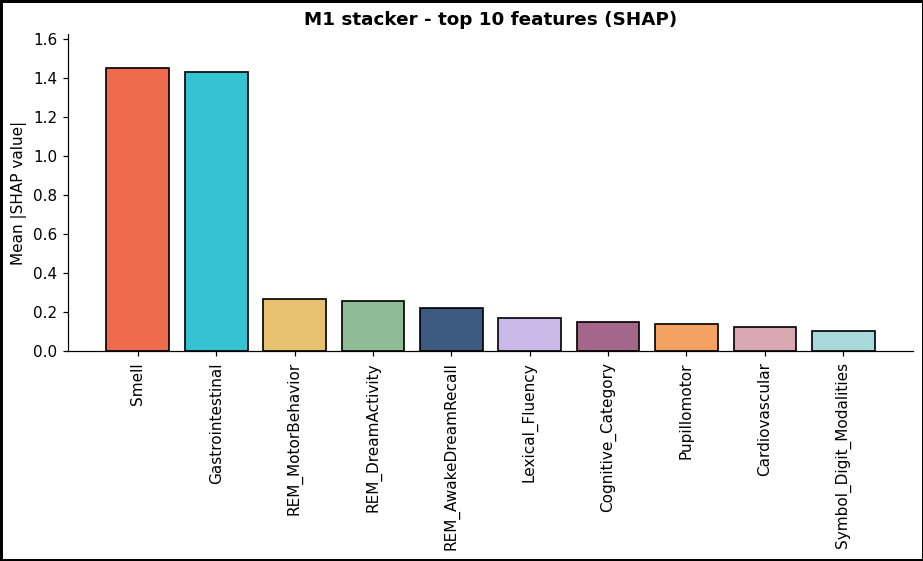

Smell                      1.449955
Gastrointestinal           1.428011
REM_MotorBehavior          0.269355
REM_DreamActivity          0.255707
REM_AwakeDreamRecall       0.224679
Lexical_Fluency            0.171796
Cognitive_Category         0.150961
Pupillomotor               0.142146
Cardiovascular             0.124943
Symbol_Digit_Modalities    0.103947
dtype: float32

In [ ]:
feat_p_test = lib.unit_mean(gt, lib.m1_feature_probs(B["m1"], Xt[COLS]))[FEATURES]

dm_m1 = xgb.DMatrix(feat_p_test.values)
contribs_m1 = B["stacker"].get_booster().predict(dm_m1, pred_contribs=True)   # last column = bias term
mean_abs_m1 = pd.Series(np.abs(contribs_m1[:, :-1]).mean(axis=0), index=FEATURES)

mean_abs_m1.sort_values(ascending=False).to_csv(os.path.join(SHAP_DIR, "m1_mean_abs_shap.csv"), header=["mean_abs_shap"])
top_m1 = plot_top10(mean_abs_m1, "M1 stacker - top 10 features (SHAP)",
                    os.path.join(SHAP_DIR, "m1_top10_shap"))
top_m1

## 4. M2 - global XGBoost SHAP

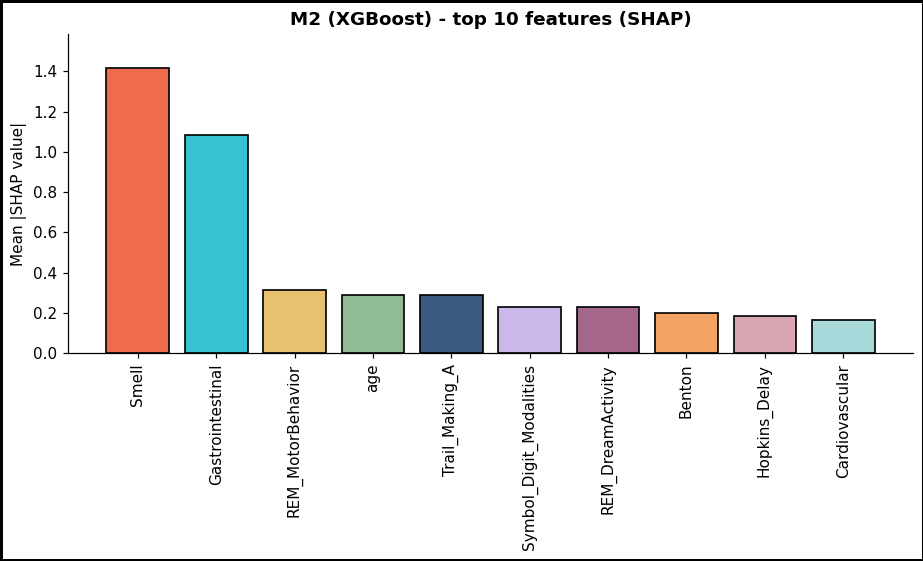

Smell                      1.415584
Gastrointestinal           1.085007
REM_MotorBehavior          0.315677
age                        0.291083
Trail_Making_A             0.290484
Symbol_Digit_Modalities    0.231635
REM_DreamActivity          0.228606
Benton                     0.200994
Hopkins_Delay              0.184185
Cardiovascular             0.164468
dtype: float32

In [ ]:
prof_m2 = prof_test.fillna(B["m2"]["medians"])
dm_m2 = xgb.DMatrix(prof_m2.values)
contribs_m2 = B["m2"]["xgb"].get_booster().predict(dm_m2, pred_contribs=True)
mean_abs_m2 = pd.Series(np.abs(contribs_m2[:, :-1]).mean(axis=0), index=COLS)

mean_abs_m2.sort_values(ascending=False).to_csv(os.path.join(SHAP_DIR, "m2_mean_abs_shap.csv"), header=["mean_abs_shap"])
top_m2 = plot_top10(mean_abs_m2, "M2 (XGBoost) - top 10 features (SHAP)",
                    os.path.join(SHAP_DIR, "m2_top10_shap"))
top_m2

## 5. M3 - collaborative-filtering SHAP (permutation explainer on M3's probability)

PermutationExplainer explainer:   1%|▍                                              | 1/123 [00:00<?, ?it/s]

PermutationExplainer explainer:   2%|▉                                      | 3/123 [00:17<02:40,  1.34s/it]

PermutationExplainer explainer:   3%|█▎                                     | 4/123 [00:20<03:48,  1.92s/it]

PermutationExplainer explainer:   4%|█▌                                     | 5/123 [00:23<04:25,  2.25s/it]

PermutationExplainer explainer:   5%|█▉                                     | 6/123 [00:26<04:50,  2.48s/it]

PermutationExplainer explainer:   6%|██▏                                    | 7/123 [00:29<05:07,  2.65s/it]

... (114 outputs left out)

PermutationExplainer explainer:  99%|████████████████████████████████████▋| 122/123 [05:58<00:01,  1.45s/it]

PermutationExplainer explainer: 100%|█████████████████████████████████████| 123/123 [05:59<00:00,  1.46s/it]

PermutationExplainer explainer: 124it [06:00,  1.47s/it]                                                    

PermutationExplainer explainer: 124it [06:00,  2.93s/it]

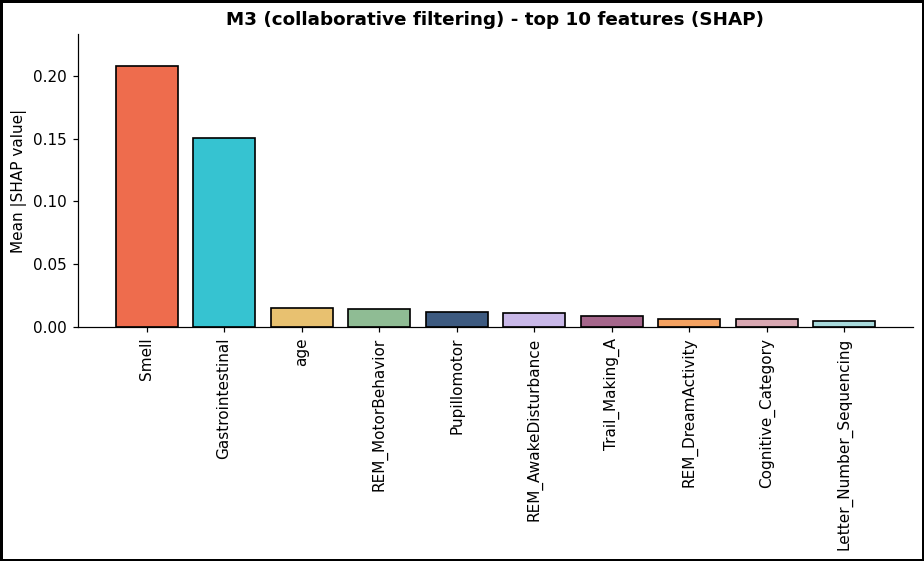

Smell                       0.208173
Gastrointestinal            0.150406
age                         0.014960
REM_MotorBehavior           0.014628
Pupillomotor                0.011910
REM_AwakeDisturbance        0.011345
Trail_Making_A              0.008789
REM_DreamActivity           0.006358
Cognitive_Category          0.006300
Letter_Number_Sequencing    0.005135
dtype: float64

In [ ]:
# M3 is a collaborative-filtering model (no trees), so it is explained with the same
# model-agnostic permutation SHAP as the final ensemble, on the probability scale.
import shap
def m3_predict(A):
    Xp = pd.DataFrame(np.asarray(A), columns=COLS)
    return lib.predict_m3(B["m3"], Xp, np.arange(len(Xp)))["M3"].values

bg_m3 = prof_test.sample(n=min(N_BACKGROUND, len(prof_test)), random_state=lib.RANDOM_STATE).values
sv_m3 = shap.Explainer(m3_predict, bg_m3, algorithm="permutation")(prof_test.values)
mean_abs_m3 = pd.Series(np.abs(sv_m3.values).mean(axis=0), index=COLS)

mean_abs_m3.sort_values(ascending=False).to_csv(os.path.join(SHAP_DIR, "m3_mean_abs_shap.csv"), header=["mean_abs_shap"])
top_m3 = plot_top10(mean_abs_m3, "M3 (collaborative filtering) - top 10 features (SHAP)",
                    os.path.join(SHAP_DIR, "m3_top10_shap"))
top_m3


## 6. Final ensemble - whole-pipeline SHAP over the 30 clinical features

Final only ever sees 3 numbers (M1, M2, M3), so there is no tree to hand to a
TreeSHAP-style method. Instead this treats `predict_pipeline` as a black box and
explains it directly in terms of the 30 clinical features + age/sex, using a
permutation explainer (never touches xgboost internals, so the shap/xgboost
`base_score` bug does not apply here).

PermutationExplainer explainer:   4%|█▉                                             | 5/123 [00:00<?, ?it/s]

PermutationExplainer explainer:   6%|██▏                                    | 7/123 [00:14<02:22,  1.23s/it]

PermutationExplainer explainer:   7%|██▌                                    | 8/123 [00:16<03:17,  1.72s/it]

PermutationExplainer explainer:   7%|██▊                                    | 9/123 [00:19<03:45,  1.98s/it]

PermutationExplainer explainer:   8%|███                                   | 10/123 [00:21<04:07,  2.19s/it]

PermutationExplainer explainer:   9%|███▍                                  | 11/123 [00:24<04:16,  2.29s/it]

... (111 outputs left out)

PermutationExplainer explainer: 100%|█████████████████████████████████████| 123/123 [06:27<00:00,  6.01s/it]

PermutationExplainer explainer: 124it [06:33,  6.07s/it]                                                    

PermutationExplainer explainer: 124it [06:33,  3.31s/it]

Final-ensemble SHAP: 123 patients explained in 394s


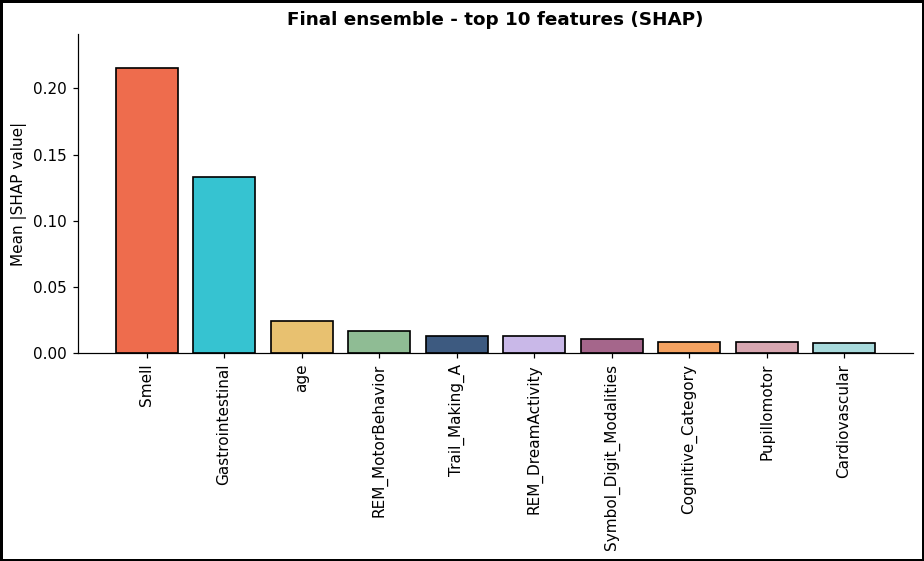

Smell                      0.215054
Gastrointestinal           0.133037
age                        0.024417
REM_MotorBehavior          0.016914
Trail_Making_A             0.012824
REM_DreamActivity          0.012717
Symbol_Digit_Modalities    0.010368
Cognitive_Category         0.008766
Pupillomotor               0.008182
Cardiovascular             0.007626
dtype: float64

In [ ]:
import shap

def final_predict(A):
    Xp = pd.DataFrame(np.asarray(A), columns=COLS)
    out = lib.predict_pipeline(B, Xp, np.arange(len(Xp)))
    return out["Final"].values

background = prof_test.sample(n=min(N_BACKGROUND, len(prof_test)), random_state=lib.RANDOM_STATE).values
explain_df = prof_test if N_EXPLAIN is None else prof_test.sample(n=min(N_EXPLAIN, len(prof_test)), random_state=lib.RANDOM_STATE)

t0 = time.time()
explainer_final = shap.Explainer(final_predict, background, algorithm="permutation")
sv_final = explainer_final(explain_df.values)
print(f"Final-ensemble SHAP: {len(explain_df)} patients explained in {time.time()-t0:.0f}s")

mean_abs_final = pd.Series(np.abs(sv_final.values).mean(axis=0), index=COLS)
mean_abs_final.sort_values(ascending=False).to_csv(os.path.join(SHAP_DIR, "final_mean_abs_shap.csv"), header=["mean_abs_shap"])
top_final = plot_top10(mean_abs_final, "Final ensemble - top 10 features (SHAP)",
                       os.path.join(SHAP_DIR, "final_top10_shap"))
top_final

## 7. All four, side by side

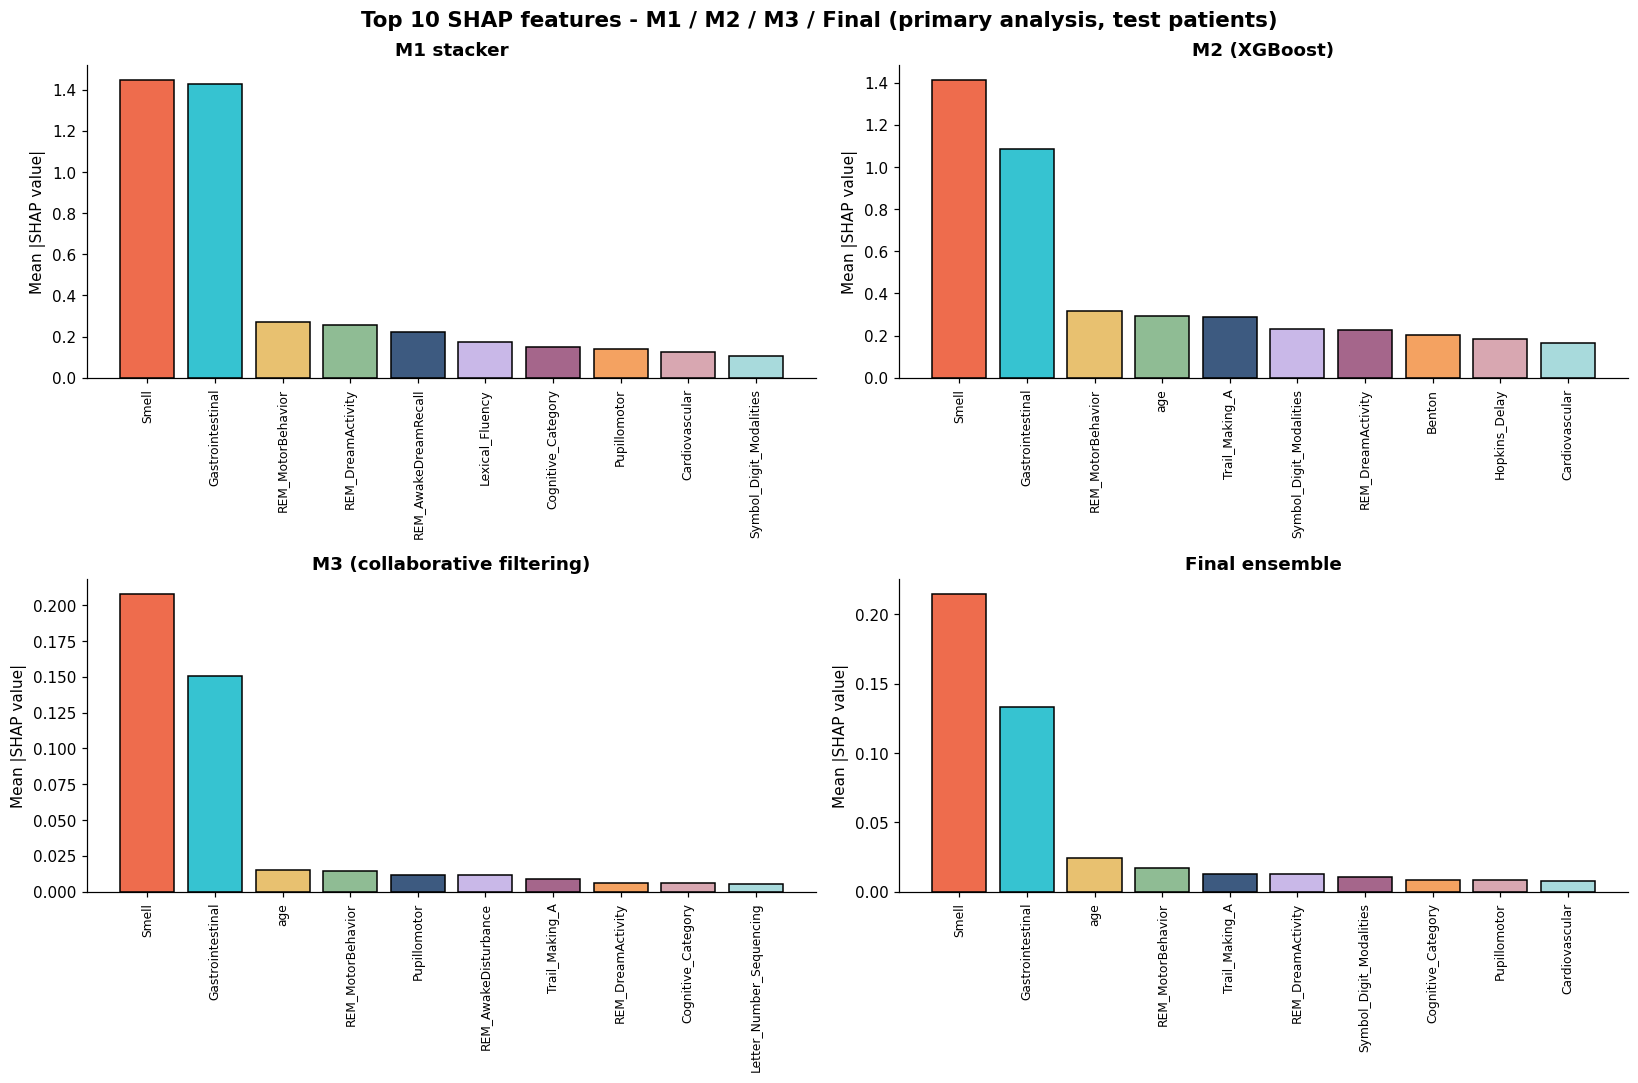

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, (label, mean_abs) in zip(axes.ravel(),
                                 [("M1 stacker", mean_abs_m1), ("M2 (XGBoost)", mean_abs_m2),
                                  ("M3 (collaborative filtering)", mean_abs_m3), ("Final ensemble", mean_abs_final)]):
    top = mean_abs.sort_values(ascending=False).head(10)
    ax.bar(range(len(top)), top.values, color=BAR_COLORS[:len(top)], edgecolor="black", linewidth=1.0)
    ax.set_xticks(range(len(top))); ax.set_xticklabels(top.index, rotation=90, fontsize=8)
    ax.set_ylabel("Mean |SHAP value|"); ax.set_title(label, fontweight="bold")
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
fig.suptitle("Top 10 SHAP features - M1 / M2 / M3 / Final (primary analysis, test patients)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
fig.savefig(os.path.join(SHAP_DIR, "all_models_top10_shap_grid.png"), dpi=150, bbox_inches="tight")
plt.show()